# Predicting Diabetes in Pima Dataset
##### San Shwe Htet - CM3015 (Machine Learning)

# Introduction

This report applies the universal machine-learning workflow from DLWP §4.5
(1st edition) to the Pima Indians Diabetes dataset, a binary-classification
problem predicting the onset of diabetes from eight clinical measurements
across 768 patient records. All models are restricted to Dense and Dropout
layers per the coursework brief. The report is organised around DLWP's
seven workflow stages (Sections 1–7), a held-out test evaluation of the
final model (Section 8), a targeted interpretation of the model's
predictions and errors (Section 9), and a concluding discussion of what
the workflow revealed and what would follow with more time or data
(Section 10).

In [41]:
import numpy as np
import pandas as pd
import tensorflow as tf
import random
from tensorflow import keras

import json

import validators

from tensorflow.keras import regularizers

import matplotlib.pyplot as plt
from IPython.display import display, Markdown

from sklearn.model_selection import train_test_split, StratifiedKFold
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                              roc_auc_score, roc_curve, confusion_matrix, ConfusionMatrixDisplay, classification_report,
                              precision_recall_curve)
from sklearn.inspection import permutation_importance
from sklearn.linear_model import LogisticRegression

In [2]:
import sys, numpy, pandas, tensorflow, validators, matplotlib, IPython, sklearn
print("python", sys.version.split()[0])
for m in [numpy, pandas, tensorflow, validators, matplotlib, IPython, sklearn]:
    print(m.__name__, m.__version__)

python 3.13.2
numpy 2.3.1
pandas 2.3.1
tensorflow 2.21.0
validators 0.36.0
matplotlib 3.11.0
IPython 9.3.0
sklearn 1.9.1


# 1. Defining the Problem and Success
According to the DLWP's section 4.5, in an attempt to tackle the machine learning problem, it is mandatory to define the problem and compile the dataset accordingly to it. 

In defining the problem, there would be two defining factors: input data and type of problem.

## 1.1 Input Data (Pima-Dataset)
The input data consists of eight numeric diagnosis measurements or features of each patient. The features are 
* Number of pregnancies
* Plasma glucose concentration
* Diastolic blood pressure
* Triceps skinfold thickness
* 2-hour serum insulin
* Body-mass index (BMI)
* Diabetes pedigree function
* Age

Based on these, the target is a binary outcome label which ``1`` represents patient tested positive for diabetes and ``0`` represents negative testing. 

## 1.2 Target 
Binary classification in which 1 if the patient is tested positive for diabetes basing the deep learning or 0 otherwise.

## 1.3 Problem Type
The problem is a binary classification in which the outcome value is either 
* diabetes
* not diabetes.

## 1.4 Choosing a measure of Success
Following DLWP's section 4.5.2, the choice of success metric must reflect the cost of the structure of the real-world problem. 
* **Class imbalance:** The 768 records are split roughly 65 % / 35 % between
  no-diabetes and diabetes. A classifier that always predicts the majority
  class would already reach approximately 65 % accuracy, so accuracy in isolation would
  give a false sense of security.
* **Asymmetric error cost.** A false negative (telling a diabetic patient
  they are healthy) is more costly than a false positive (recommending a
  healthy patient for a follow-up test). A single accuracy score cannot
  distinguish between these two error types.

## 1.5 Working Hypotheses 
Following the DLWP's Section 4.5.1, two hypotheses are made explicit before modelling. 
* **Learning Hypothesis:** the eight measurements collected contain enough information, in combination, to predict the diabetes outcome substantially better than chance.
* **Sufficiency Hypothesis:** the 768 available records are enough to learn that relationship well.

# 2. Extracting and Assembling the dataset

The data is extracted directly from the raw webpage using it's URL using panda which is then assembled into the dataframe using the first row as the header. The header is then compiled into array under ```Column Header``` name. 

We use ```nan_checker``` helper function to see if the dataframe has any missing values or NaN by rows and columns.

checked if there are Nan values inside it. 

In [3]:
# [MYWORK]
# helper function to check if there is nan values in df

def nan_checker(df):
    if df.isna().any().any():
        print("There are missing values (NaN)")
        return True
    print("No missing values")
    return False

In [4]:
SEED = 42
np.random.seed(SEED)
tf.random.set_seed(SEED)
# pd.set_option("display.precision")

# using raw to save up storage
# https://docs.github.com/en/enterprise-cloud@latest/repositories/working-with-files/using-files/viewing-and-understanding-files#viewing-or-copying-the-raw-file-content
dataset_url = "https://raw.githubusercontent.com/npradaschnor/Pima-Indians-Diabetes-Dataset/refs/heads/master/diabetes.csv"

url_validator = validators.url
url_validator(dataset_url)

# 9 columns that might relate to the diabetes
dataset_df = pd.read_csv(dataset_url, header=0)
COLUMN_NAMES = [item for item in dataset_df.columns]
print("numbers of columns:  ", len(COLUMN_NAMES))
print("columns:", COLUMN_NAMES)

# checking the dimension
print(dataset_df.shape)
row, col = dataset_df.shape
print("total sample amount  ", row * col)

# first initial filter on missing value (NaN)
assert nan_checker(dataset_df) == False

numbers of columns:   9
columns: ['Pregnancies', 'Glucose', 'BloodPressure', 'SkinThickness', 'Insulin', 'BMI', 'DiabetesPedigreeFunction', 'Age', 'Outcome']
(768, 9)
total sample amount   6912
No missing values


In [5]:
print(dataset_df['Outcome'].count())
print(dataset_df['Outcome'].value_counts())

class_counts = dataset_df['Outcome'].value_counts()
print(class_counts[0])
print(class_counts[1])
print(len(dataset_df))

summary = pd.DataFrame({
    'Count': class_counts,
    'Percentage': (class_counts / len(dataset_df) * 100)
})

print(summary)

768
Outcome
0    500
1    268
Name: count, dtype: int64
500
268
768
         Count  Percentage
Outcome                   
0          500   65.104167
1          268   34.895833


# 3. Evaluation Protocol

Following DLWP section4.5.3, an evaluation protocol must be chosen before training
begins. This section justifies the choice of protocol for this project, given
the small-data, class-imbalanced nature of the problem described in section1.

## 3.1 Choice of protocols

DLWP section4.2.1 identifies three standard evaluation protocols:

<ol>
    <li>
        <strong>Simple hold-out validation</strong> — classic train/test split.
        <ul>
            <li><strong>Pros:</strong> fastest to run.</li>
            <li><strong>Cons:</strong> a single split is noisy on small datasets.</li>
        </ul>
    </li>
    <li>
        <strong>K-fold cross-validation</strong>
        <ul>
            <li><strong>Pros:</strong> more robust when data is limited.</li>
            <li><strong>Cons:</strong> K× training cost.</li>
        </ul>
    </li>
    <li>
        <strong>Iterated K-fold with shuffling</strong>
        <ul>
            <li><strong>Pros:</strong> most robust for very small datasets.</li>
            <li><strong>Cons:</strong> highest computational cost due to repeated K-fold runs.</li>
        </ul>
    </li>
</ol>

This project uses **two of these protocols at two different stages** of the workflow:

* A **three-way hold-out split** (60 % train / 20 % validation / 20 % test) for the
  initial broad architecture search in Sections 5–7.
* **5-fold cross-validation** on the shortlist of promising candidates in Section 7.4,
  before selecting the final architecture.

A pure two-way train/test split was rejected: reusing the same test set to compare
configurations would let test-set results influence model-selection decisions, tuning
the process to that specific test set and giving an overly optimistic estimate of
generalisation. The three-way split isolates the test set from selection entirely,
so it can serve as a genuine held-out evaluation in Section 8.

The hold-out split is used for the broad search because it is computationally cheap
and adequate for ranking candidate architectures. 5-fold cross-validation is then
applied to the shortlist because, at 768 records, a single validation split carries
enough variance to be unreliable for the final selection, and averaging over five
folds materially reduces that variance. Iterated K-fold was not necessary because
the shortlist size stayed small.

## 3.2 Data split

                    ORIGINAL DATA
                        100%
                         │
             ┌───────────┴───────────┐
             │                       │
            80%                     20%
        train + val                 test
             │
        ┌────┴────┐
        │         │
       75%       25%
        │         │
        ↓         ↓
      X_TRAIN   X_VAL
       60%       20%

* Sections 5–7 train on `X_TRAIN` and evaluate on `X_VAL`. 
* Section 7.4 re-runs the
shortlisted candidates using 5-fold cross-validation on `X_TRAIN ∪ X_VAL` before
selecting the final architecture. 
* Section 8 trains the winning architecture once
on `X_TRAIN ∪ X_VAL` and evaluates on `X_TEST`, which is untouched until that point.

In [6]:
# x-axis: features excluding outcome
# y-axis: outcome value col: 1 or 0
X = dataset_df.drop(columns=['Outcome']).values.astype('float32')
y = dataset_df['Outcome'].values.astype('float32')

# first row
# print(X[0], y[0])

# 60/20/20 stratified split based on outcome
# https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.train_test_split.html
X_trainval, X_test, y_trainval, y_test = train_test_split(
    X, y, 
    test_size = 0.2, 
    train_size = 0.8,
    stratify=y, 
    random_state=42
)

# test_size = 0.2/0.8 = 0.25
X_train, X_val, y_train, y_val = train_test_split(
    X_trainval, y_trainval, 
    test_size = 0.25, 
    train_size=0.75,
    stratify=y_trainval, 
    random_state=42
)

# sanity check: seeing if stratify works
split_summary = pd.DataFrame({
    'n': [len(X_train), len(X_val), len(X_test)],
    'mean_positive_outcome': [y_train.mean(), y_val.mean(), y_test.mean()],
}, index = ['train', 'validation', 'test'])

split_summary

,n,mean_positive_outcome
train,460,0.347826
validation,154,0.350649
test,154,0.350649


# 4. Data Preparation

DLWP 4.5 set out three standard tensor-preparation steps: get data into tensor form

## 4.1 Missing Value in the Form of Numeral Zero instead of NaN

Although the dataset does not have the NaN form of missing value, the missing value is instead presented in numeral zero (similar to house-price example in DLWP). The factors such as Glucose, BloodPressure, SkinThickness, Insulin, BMI in reality should present above the 0 as value for a living patient sample. If these missing values were fed to the network, they would cause skewed results. Hence, In order to do this. The
3

In [7]:
zero_counts = (dataset_df[['Glucose','BloodPressure','SkinThickness','Insulin','BMI', 'Age']] == 0).sum()
print(zero_counts)

Glucose            5
BloodPressure     35
SkinThickness    227
Insulin          374
BMI               11
Age                0
dtype: int64


In [8]:
# columns that used 0 to represent a missing value 
cols_with_zeros = [
    'Glucose',
    'BloodPressure',
    'SkinThickness',
    'Insulin',
    'BMI'
]
# feature col names
feature_cols = [c for c in COLUMN_NAMES if c!= 'Outcome']
# idx of col with zero in relation to exisiting feature col idxs
zero_col_idx = [feature_cols.index(c) for c in cols_with_zeros]

# make a copy of a training data
X_train_copy = X_train.copy()

# Replacing 0 with NaN (missing value) in order to assert correctly
for idx in zero_col_idx:
    X_train_copy[X_train_copy[:, idx] == 0, idx] = np.nan 

# sanity check: see if zeros are replaced with nan
for column in cols_with_zeros:
    idx = feature_cols.index(column)
    print(
        column,
        "NaNs:", np.isnan(X_train_copy[:, idx]).sum(),
        "Zeros:", (X_train_copy[:, idx] == 0).sum()
    )

# median excluding nan
medians = np.nanmedian(X_train_copy, axis=0)

# replacing missing Nan with the median
for col_idx in range(X_train_copy.shape[1]):
    # find missing values
    missingval = np.isnan(X_train_copy[:, col_idx])
    X_train_copy[missingval, col_idx] = medians[col_idx]



Glucose NaNs: 4 Zeros: 0
BloodPressure NaNs: 18 Zeros: 0
SkinThickness NaNs: 131 Zeros: 0
Insulin NaNs: 215 Zeros: 0
BMI NaNs: 6 Zeros: 0


In [9]:
# extracting the mean and s.t.d. from training data
mean = X_train_copy.mean(axis=0)
std = X_train_copy.std(axis=0)

# Standardiing the training data centered around 0
print("Before standardise: ", X_train_copy)
print("\n")
X_train_p = (X_train_copy - mean) / std
print("After standardise: ", X_train_p)


Before standardise:  [[  1.    116.     70.    ...  27.4     0.204  21.   ]
 [  6.    162.     62.    ...  24.3     0.178  50.   ]
 [  4.    146.     85.    ...  28.9     0.189  27.   ]
 ...
 [  3.    124.     80.    ...  33.2     0.305  26.   ]
 [  2.    109.     92.    ...  42.7     0.845  54.   ]
 [  0.    152.     82.    ...  41.5     0.27   27.   ]]


After standardise:  [[-0.84018815 -0.19888277 -0.15099812 ... -0.7368226  -0.8225719
  -1.0330889 ]
 [ 0.67307156  1.3749245  -0.800908   ... -1.1877714  -0.8988132
   1.4424648 ]
 [ 0.06776769  0.8275133   1.067583   ... -0.5186216  -0.8665573
  -0.5209054 ]
 ...
 [-0.23488425  0.07482284  0.66138923 ...  0.10688806 -0.52640367
  -0.6062693 ]
 [-0.5375362  -0.43837517  1.6362541  ...  1.4888277   1.05707
   1.7839204 ]
 [-1.14284     1.0327924   0.8238667  ...  1.3142668  -0.6290362
  -0.5209054 ]]


In [10]:
# Creating the function used for val and test data
# uses the mean, median and s.t.d. from training set
# (MYWORk) code reused

def prep_data(x):
    x = x.copy()

    # zero --> Nan
    for col_idx in zero_col_idx:
        x[x[:, col_idx] == 0, col_idx] = np.nan 

    # nan --> median
    for col_idx in range(X_train_copy.shape[1]):
        # find missing values
        missingval = np.isnan(x[:, col_idx])
        x[missingval, col_idx] = medians[col_idx]

    # standardise
    x = (x-mean) / std
    return x.astype("float")

X_val_p     = prep_data(X_val)
X_test_p    = prep_data(X_test)

# sanity check on random row of validation
num = random.randint(0, X_val_p.shape[0] - 1)
print("Prepped Validation set")
print(X_val_p [num])
print("Prepped Test Set")
print(X_test_p [num])


Prepped Validation set
[ 0.97572351  1.30649817 -1.45081794  0.26225835  0.47085506 -0.28587383
  0.30345377  0.50346166]
Prepped Test Set
[-1.14284003 -0.71208078 -0.55719179 -0.17404839 -0.16290349 -1.14413106
 -0.72580403 -0.947725  ]


In [11]:
# check that there are no missing values left
assert not np.isnan(X_train_p).any(), "Training data still contains NaNs"
assert not np.isnan(X_val_p).any(), "Validation data still contains NaNs"
assert not np.isnan(X_test_p).any(), "Test data still contains NaNs"

print("No NaNs")

# check if there is no impossible zero
for column in cols_with_zeros:
    idx = feature_cols.index(column)
    assert np.isnan(X_val_p[:, idx]).sum() == 0, f"{column} still has NaNs in validation data"
    assert (X_val_p[:, idx] == 0).sum() == 0, f"{column} still has zeros in validation data"
    assert np.isnan(X_test_p[:, idx]).sum() == 0, f"{column} still has NaNs in test data"
    assert (X_test_p[:, idx] == 0).sum() == 0, f"{column} still has zeros in test data"

print("No Impossible Zeros")
print("Data is ready for modelling.")

No NaNs
No Impossible Zeros
Data is ready for modelling.


# 5. Developing a Model that Beats a Baseline (Statistical Power)

Based on the section 4.5.5 of DLWP, the project focuses on achieving "statistical power" in which is achieved via building the smallest, simplest model that can perform better than a trival baseline. In order to do that, the project used 

* **Majority-class baseline** which always predict the more common class (no diabetes). This is the dumbest possible baseline and the model must clear it.
* **Logistic-regression baseline** which fits a linear combination of the eight input features passed through a `sigmoid`. (Note: this model is used in measuring the feature importance later in the **section 9**)


Per DLWP's guidance for binary classification: every network created in this report minimally consists of three key choices. 
* **Last-Layer activation:**: the `sigmoid function` is used for binary classification in which the values are mapped between 0 and 1
* **Loss function**: `binary_crossentropy` Binary cross-entropy (BCE) was selected because the task is binary classification and the output layer uses a sigmoid activation function to produce a probability for the positive class. BCE is preferred over mean squared error (MSE) because it is specifically designed for classification probabilities and provides stronger, more informative gradients when predictions are confidently wrong, allowing the model to learn more effectively.
* **Optimizer**: `rmsprop` which was used consistently in DLWP.

In [37]:
# [MYWORK] create  different iteration of the model 
# (iterated and added more features later)

def construct_neural_network(hidden_units=(), input_dim=8, dropout = 0.0, l2=0.0):
    """Build a Sequential Desnse/Dropout binary classifier. 
    
    hidden unit: tuple of ints, e.g. (16,) or (64, 64)
    """

    # Implementing regularisers
    reg = regularizers.l2(l2) if l2>0 else None

    # INPUT LAYER
    layers = [keras.Input(shape=(input_dim,))] # 1st layer

    # MIDDLE HIDDEN LAYER
    layer_name = 1
    # that can be scaled later to avoid information bottle neck
    # DLWP (section 3.5.7)
    for unit in hidden_units:
        layers.append(keras.layers.Dense(
            unit, activation='relu', 
            kernel_regularizer= reg, 
            name=f"relu_layer_{layer_name}"))

        # Added for the "Section 7" (implementing dropout)
        # https://keras.io/api/layers/regularization_layers/dropout/
        if dropout > 0:
            layers.append(keras.layers.Dropout(dropout))
        layer_name = layer_name + 1

    # LAST LAYER (SIGMOID)
    layers.append(keras.layers.Dense(1, activation='sigmoid'))

    # compiling the model
    model = keras.Sequential(layers)
    model.compile(
        optimizer = 'rmsprop',
        loss='binary_crossentropy',
        metrics = ['accuracy']
    )
    return model


# (MyWork) function for constructing report based on history
def report_model_performance(history, model_name="Model"):
    # Find the epoch with the highest validation accuracy
    best_epoch = history.history['val_accuracy'].index(
        max(history.history['val_accuracy'])
    ) + 1
    
    # Metrics at the best validation-accuracy epoch
    best_val_accuracy = history.history['val_accuracy'][best_epoch - 1]
    train_accuracy_at_best = history.history['accuracy'][best_epoch - 1]
    val_loss_at_best = history.history['val_loss'][best_epoch - 1]

    print(f"\n===== {model_name} Performance =====")
    print(f"Best epoch:              {best_epoch}")
    print(f"Training accuracy:       {train_accuracy_at_best:.4f}")
    print(f"Validation accuracy:     {best_val_accuracy:.4f}")
    print(f"Validation loss:         {val_loss_at_best:.4f}")
    return best_epoch, train_accuracy_at_best, best_val_accuracy, val_loss_at_best

# [MYWORK] the function made to avoid repeating the same code for Section 7
def run_regularisation_experiment(
    model_configs,
    hidden_units,
    X_train,
    y_train,
    X_val,
    y_val,
    epochs=100,
    verbose=0
):
    """
    Train multiple models with different regularisation settings.

    Parameters
    ----------
    model_configs : list
        [('Model-1', dropout, l2), ...]
    hidden_units : tuple
        e.g. (64,), (16,16), (64,64)
    """

    trained_models = []

    for name, dropout, l2 in model_configs:

        model = construct_neural_network(
            hidden_units=hidden_units,
            dropout=dropout,
            l2=l2
        )

        history = model.fit(
            X_train,
            y_train,
            epochs=epochs,
            validation_data=(X_val, y_val),
            verbose=verbose
        )

        print(f"Done fitting: {name}")

        trained_models.append(
            (name, model, history, dropout, l2)
        )

    return trained_models

# [MYWORK]results table (added for both wide and deep to avoid error)
def build_reg_table(models_and_hists):
    rows = []
    for name, model, hist, dropout, l2 in models_and_hists:
        val_loss   = np.array(hist.history['val_loss'])
        train_loss = np.array(hist.history['loss'])
        val_acc    = np.array(hist.history['val_accuracy'])
        best_epoch = int(np.argmin(val_loss)) + 1
        i          = best_epoch - 1
        rows.append({
            'Model': name,
            'Dropout':dropout,
            'L2':l2,
            'Params': model.count_params(),
            'Best Epoch': best_epoch,
            'Min val_loss': round(val_loss[i], 4),
            'Best Val Accuracy': round(val_acc[i], 4),
            'Train Loss @ Best': round(train_loss[i], 4),
            'Loss Gap @ Best': round(abs(train_loss[i] - val_loss[i]), 4),
        })
    return pd.DataFrame(rows).sort_values('Min val_loss').reset_index(drop=True)

# (MYWORK) function version for cell 13, 14, 15
def fit_prep(X_train):
    # from cell 13 section
    X = X_train.copy()
    for col_idx in zero_col_idx:
         X[X[:, col_idx] == 0, col_idx] = np.nan 
    medians = np.nanmedian(X, axis=0)
    for col_idx in range(X.shape[1]):
        X[np.isnan(X[:, col_idx]), col_idx] = medians[col_idx]

    # from cell 14
    mean, std = X.mean(0), X.std(0)


    def prep(Z):
        Z = Z.copy()
        for col_idx in zero_col_idx:
            Z[Z[:, col_idx] == 0, col_idx] = np.nan
        for col_idx in range(Z.shape[1]):
            Z[np.isnan(Z[:, col_idx]), col_idx] = medians[col_idx]
        return ((Z - mean) / std).astype('float32')
    return prep, {"medians": medians, "mean": mean, "std": std}


In [13]:
# --- Baseline 1: majority class ------------------------------------------------
majority_class = float(pd.Series(y_train).mode()[0])
maj_val_acc = (y_val == majority_class).mean()
print(f"\n===== Majority Class Performance =====")
print(f"Training accuracy:       {maj_val_acc:.4f}")

# --- Baseline 2: Logistic Regression (Addition) --------------------------------
lr_baseline = LogisticRegression(max_iter=1000).fit(X_train_p, y_train)
lr_val_acc  = accuracy_score(y_val, lr_baseline.predict(X_val_p))
print(f"\n===== Logistic Regression Performance =====")
print(f"Validation accuracy:     {lr_val_acc:.4f}")

# first minimum model for statistical power
model_0 = construct_neural_network()
history_0 = model_0.fit(
    X_train_p, 
    y_train,
    epochs=50,
    batch_size = 16,
    validation_data = (X_val_p, y_val),
    verbose = 0
)
best_epoch, train_accuracy_at_best, best_val_accuracy, val_loss_at_best = report_model_performance(history_0, model_0)
 
# dynamic report with f-string
display(Markdown(f"""
## Statistical Power Report

Two baselines are established for this stage. The majority-class baseline, which always predicts *no diabetes*, reaches **{maj_val_acc*100:.1f}%** validation accuracy. This is the "dumb baseline" defined in DLWP section 4.5.5 that any model with statistical power must clear. The logistic-regression baseline reaches **{lr_val_acc*100:.1f}%**. Logistic regression is a stronger reference point drawn from standard tabular machine-learning practice, since linear models are often within a few points of a well-tuned neural network on small tabular datasets.

Model 1 uses a single `Dense(1, sigmoid)` layer with **9 trainable parameters** (8 weights and 1 bias). It reaches **{best_val_accuracy*100:.1f}%** validation accuracy at epoch {best_epoch}, with a training accuracy of **{train_accuracy_at_best*100:.1f}%** and a validation loss of **{val_loss_at_best:.4f}**. Compared to the majority-class baseline, this is an improvement of **{(best_val_accuracy - maj_val_acc)*100:+.2f}** percentage points, so the DLWP definition of statistical power is satisfied. Compared to logistic regression, the improvement is **{(best_val_accuracy - lr_val_acc)*100:+.2f}** percentage points.

The close result against logistic regression is expected. A `Dense(1, sigmoid)` layer trained with binary cross-entropy is architecturally the same model as logistic regression, so any small difference reflects the choice of optimiser rather than a difference in what the two models can represent. Taken together, the two comparisons show that the dataset does contain learnable signal (both linear models comfortably clear the majority-class baseline), and that any further improvement will need to come from non-linear capacity. Section 6 tests this by scaling up model capacity through additional hidden layers and units.
"""))


===== Majority Class Performance =====
Training accuracy:       0.6494

===== Logistic Regression Performance =====
Validation accuracy:     0.7792

===== <Sequential name=sequential, built=True> Performance =====
Best epoch:              49
Training accuracy:       0.7870
Validation accuracy:     0.7987
Validation loss:         0.4401



## Statistical Power Report

Two baselines are established for this stage. The majority-class baseline, which always predicts *no diabetes*, reaches **64.9%** validation accuracy. This is the "dumb baseline" defined in DLWP section 4.5.5 that any model with statistical power must clear. The logistic-regression baseline reaches **77.9%**. Logistic regression is a stronger reference point drawn from standard tabular machine-learning practice, since linear models are often within a few points of a well-tuned neural network on small tabular datasets.

Model 1 uses a single `Dense(1, sigmoid)` layer with **9 trainable parameters** (8 weights and 1 bias). It reaches **79.9%** validation accuracy at epoch 49, with a training accuracy of **78.7%** and a validation loss of **0.4401**. Compared to the majority-class baseline, this is an improvement of **+14.94** percentage points, so the DLWP definition of statistical power is satisfied. Compared to logistic regression, the improvement is **+1.95** percentage points.

The close result against logistic regression is expected. A `Dense(1, sigmoid)` layer trained with binary cross-entropy is architecturally the same model as logistic regression, so any small difference reflects the choice of optimiser rather than a difference in what the two models can represent. Taken together, the two comparisons show that the dataset does contain learnable signal (both linear models comfortably clear the majority-class baseline), and that any further improvement will need to come from non-linear capacity. Section 6 tests this by scaling up model capacity through additional hidden layers and units.


# 6. Scaling Up: Overfitting Model

In DLWP's section 4.5.6, it is recommended to deliberately build a model with more capacity than necessary, training it long enough to overfit. 

The project implements four architectures for four different models with increased capacity, which are trained for 150 epochs each. For this stage, there are no regularisation implemented, so that the point at which each one starts to overfit can be read directly for validation curves.

In [14]:
# Number of epochs
overfit_epochs = 150

# Model A: one hidden layer with 16 units
model_A = construct_neural_network(hidden_units=(16,))
history_A = model_A.fit(
    X_train_p,
    y_train,
    epochs=overfit_epochs,
    batch_size=16,
    validation_data=(X_val_p, y_val),
    verbose=0
)

# Model B: two hidden layers with 16 units each
model_B = construct_neural_network(hidden_units=(16, 16))
history_B = model_B.fit(
    X_train_p,
    y_train,
    epochs=overfit_epochs,
    batch_size=16,
    validation_data=(X_val_p, y_val),
    verbose=0
)

# Model C: two hidden layers with 64 units each
model_C = construct_neural_network(hidden_units=(64, 64))
history_C = model_C.fit(
    X_train_p,
    y_train,
    epochs=overfit_epochs,
    batch_size=16,
    validation_data=(X_val_p, y_val),
    verbose=0
)

# Model D: three hidden layers with 128 units each
model_D = construct_neural_network(hidden_units=(128, 128, 128))
history_D = model_D.fit(
    X_train_p,
    y_train,
    epochs=overfit_epochs,
    batch_size=16,
    validation_data=(X_val_p, y_val),
    verbose=0
)

report_model_performance(history_A, "Model A: Dense(16)")
report_model_performance(history_B, "Model B: Dense(16)-Dense(16)")
report_model_performance(history_C, "Model C: Dense(64)-Dense(64)")
report_model_performance(history_D, "Model D: Dense(128)-Dense(128)-Dense(128)")



===== Model A: Dense(16) Performance =====
Best epoch:              16
Training accuracy:       0.7761
Validation accuracy:     0.8117
Validation loss:         0.4248

===== Model B: Dense(16)-Dense(16) Performance =====
Best epoch:              10
Training accuracy:       0.7848
Validation accuracy:     0.8052
Validation loss:         0.4225

===== Model C: Dense(64)-Dense(64) Performance =====
Best epoch:              1
Training accuracy:       0.7087
Validation accuracy:     0.7922
Validation loss:         0.4992

===== Model D: Dense(128)-Dense(128)-Dense(128) Performance =====
Best epoch:              9
Training accuracy:       0.8261
Validation accuracy:     0.7987
Validation loss:         0.4529


(9, 0.8260869383811951, 0.798701286315918, 0.4529024064540863)

In [15]:
ARCHITECTURES = {
    # --- Increasing width: 1 hidden layer ---
    'Dense(8)': (8,),
    'Dense(16)': (16,),
    'Dense(32)': (32,),
    'Dense(64)': (64,),
    'Dense(128)': (128,),

    # --- Increasing depth: 2 hidden layers ---
    'Dense(16)-Dense(16)': (16, 16),
    'Dense(32)-Dense(32)': (32, 32),
    'Dense(64)-Dense(64)': (64, 64),

    # --- Increasing depth: 3 hidden layers ---
    'Dense(16)-Dense(16)-Dense(16)': (16, 16, 16,),
}
OVERFIT_EPOCHS = 150

overfit_hist_dict = {} # for compiling the models
overfit_rows = []

# (MYWORK) compiling into row
# initially multiple separated models now condensed into loop
for name, units in ARCHITECTURES.items():
    model = construct_neural_network(hidden_units=units)
    # hist = fit_silent(model, X_train_p, y_train, X_val_p, y_val, epochs=OVERFIT_EPOCHS)
    hist = model.fit(X_train_p, y_train, epochs=OVERFIT_EPOCHS, batch_size=16,
                      validation_data=(X_val_p, y_val), verbose=0)

    overfit_hist_dict[name] = hist.history
    val_loss = np.array(hist.history['val_loss'])
    train_loss = np.array(hist.history['loss'])
    best_epoch = int(np.argmin(val_loss)) + 1 # added later for the graph
    overfit_rows.append({
        'Architecture': name,
        'Params': model.count_params(),
        'Best Epoch': best_epoch,
        'Min val_loss': val_loss[best_epoch - 1],
        'Best Val Accuracy': hist.history['val_accuracy'][best_epoch - 1],
        'train_loss at Best Epoch': train_loss[-1],
        'Val loss at Best Epoch': val_loss[-1]
    })

In [16]:
# separated to avoid running again
overfit_tbl = pd.DataFrame(overfit_rows).sort_values('Best Val Accuracy', ascending=False)
overfit_tbl

,Architecture,Params,Best Epoch,Min val_loss,Best Val Accuracy,train_loss at Best Epoch,Val loss at Best Epoch
0,Dense(8),81,31,0.440309,0.798701,0.420045,0.448498
2,Dense(32),321,13,0.414274,0.798701,0.377974,0.430853
5,Dense(16)-Dense(16),433,13,0.433415,0.792208,0.324378,0.476966
1,Dense(16),161,54,0.411755,0.785714,0.387586,0.421979
4,Dense(128),1281,35,0.423214,0.785714,0.314704,0.443126
8,Dense(16)-Dense(16)-Dense(16),705,34,0.427658,0.785714,0.197374,0.675712
7,Dense(64)-Dense(64),4801,4,0.434401,0.779221,0.046938,1.048671
3,Dense(64),641,8,0.416458,0.772727,0.341478,0.437265
6,Dense(32)-Dense(32),1377,8,0.438483,0.772727,0.202183,0.611135


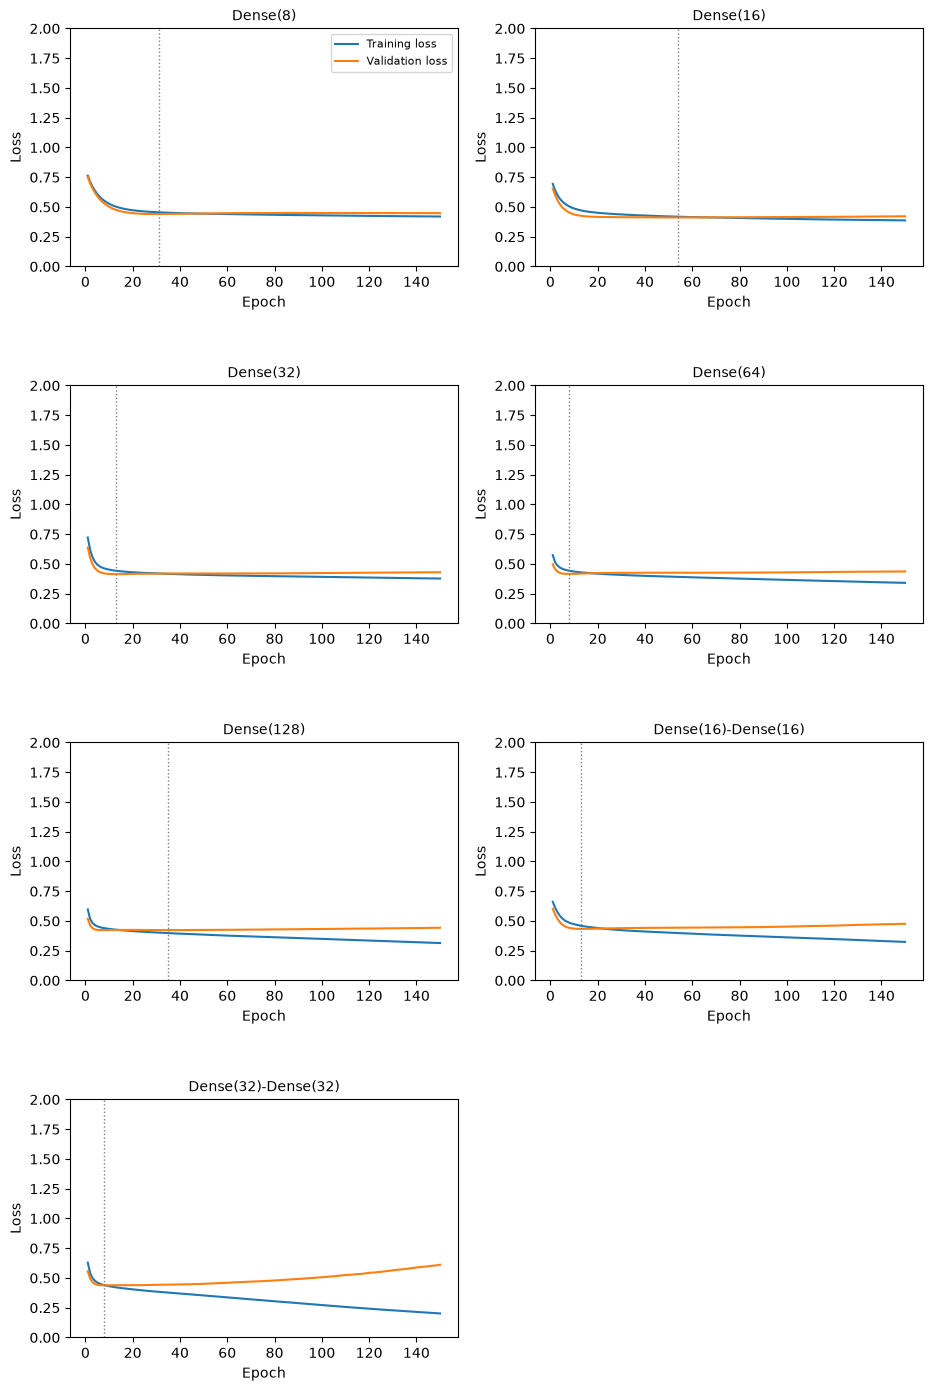

In [17]:
fig, axes = plt.subplots(4, 2, figsize=(11, 17), sharex=False, sharey=False)
axes.ravel()[-1].set_visible(False)

# increased padding for label space
fig.subplots_adjust(hspace=0.5)

# for (name,hist) in overfit_hist_dict.items():
#     print(name)
#     print(hist.keys())

zipped_item = zip( axes.ravel(), overfit_hist_dict.items())
# using for loop to iterate through the overfit_hist_dict.items():
for ax,(name, hist) in zipped_item:
    epochs = range(1, overfit_epochs + 1)

    # setting up the tick label and titles
    ax.set_title(name, fontsize=10)
    ax.set_ylim(0, 2.0)

    # best epoch sits at lowest val loss (not train loss)
    best_epoch = np.argmin(hist['val_loss']) + 1

    # orange: val loss, blue: train loss, 
    ax.plot(epochs, hist['loss'], label='Training loss', color='tab:blue')
    ax.plot(epochs, hist['val_loss'], label='Validation loss', color='tab:orange')
    # created dynamic best epoch line instead of drawing manually
    ax.axvline(best_epoch, color='grey', linestyle=':', linewidth=1)
    ax.set_xlabel('Epoch')
    ax.set_ylabel('Loss')

axes[0, 0].legend(fontsize=8)
plt.show()

In [18]:
most_overfitted_model = overfit_tbl.loc[overfit_tbl['Best Epoch'].idxmin()]
smallest_model = overfit_tbl.iloc[0]
largest_model = overfit_tbl.iloc[-1]

# the summary of which row is chosen
print("~~~~~~~~~~ Verifying ~~~~~~~~ \n")
print(most_overfitted_model)

~~~~~~~~~~ Verifying ~~~~~~~~ 

Architecture                Dense(64)-Dense(64)
Params                                     4801
Best Epoch                                    4
Min val_loss                           0.434401
Best Val Accuracy                      0.779221
train_loss at Best Epoch               0.046938
Val loss at Best Epoch                 1.048671
Name: 7, dtype: object


In [19]:
# ============================================================
# Extract the best wide and deep architectures from Section 6
# ============================================================

overfit_table = (
    pd.DataFrame(overfit_rows)
    .reset_index(drop=True)
)

# Separate the wide (1 hidden layer) and deep (2 hidden layers) models
wide_models_table = overfit_table[
    overfit_table['Architecture'].
    str.contains(r'Dense\(\d+\)$', regex=True)
]

deep_models_table = overfit_table[
    overfit_table['Architecture'].
    str.contains(r'Dense\(\d+\)-Dense\(\d+\)', regex=True)
]

# Select the architecture with the lowest minimum validation loss

best_wide_row = wide_models_table.loc[
    wide_models_table['Best Val Accuracy'].idxmax()
]

best_deep_row = deep_models_table.loc[
    deep_models_table['Best Val Accuracy'].idxmax()
]


# Extract architecture names
best_wide_name = best_wide_row['Architecture']
best_deep_name = best_deep_row['Architecture']

# Extract hidden-layer configurations from the ARCHITECTURES dict
best_wide_units = ARCHITECTURES[best_wide_name]
best_deep_units = ARCHITECTURES[best_deep_name]

print("Best wide model:")
print(best_wide_name)
print(f"Hidden units: {best_wide_units}")

print("\nBest deep model:")
print(best_deep_name)
print(f"Hidden units: {best_deep_units}")

Best wide model:
Dense(8)
Hidden units: (8,)

Best deep model:
Dense(16)-Dense(16)
Hidden units: (16, 16)


# 7. Regularising the Model

In Section 6, the larger `Dense(64)-Dense(64)` model showed strong overfitting: training loss continued to decrease while validation loss increased. Following DLWP Chapter 4, regularisation can be used to reduce overfitting.

For this section, the project implements Dropout to `Dense(64)-Dense(64)` model and compare it with the original unregularised model counterpart. This keeps the experiment simple and changes only `regularisation`. 

The project uses `L2 Regularisation` and `Dropout`.

### Dropout (Standard)
`Dropout` is a regularisation technique that randomly disables a proportion of neurons during training. In this project, dropout is tested at rates of **0.0**, **0.3**, and **0.5**. A dropout rate of **0.3** means that approximately **30%** of the neurons in the relevant layer are temporarily ignored during each training step. 

The idea is to prevent the `Dense(64)-Dense(64)` model from becoming too dependent on particular neurons or combinations of neurons. This encourages the network to learn more general patterns in the Pima Indians Diabetes dataset rather than memorising patterns specific to the training data.

Hypothetically, increasing dropout should reduce overfitting, which may result in a smaller gap between `training` and `validation loss`. However, too much dropout can make the model learn less effectively and may cause **underfitting**. Therefore, a moderate dropout rate such as **0.3** may provide a better balance than either no dropout or a higher rate such as **0.5**.

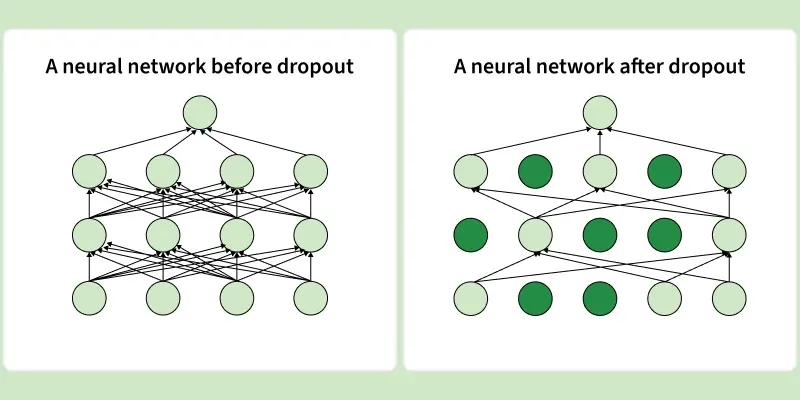
from GeeksforGeeks (2024)

### L2 Regularisation 
L2 regularisation adds a penalty to the model's loss function based on the size of its weights. The penalty discourages the network from developing excessively large weights.

In this project, L2 is tested at 0.0 and 0.001. An L2 value of 0.001 adds a small penalty to large weights while the model is being trained. This encourages the Dense(64)-Dense(64) model to use smaller, less extreme weights and can therefore make the model less likely to overfit the training data.

Hypothetically, adding L2 regularisation should improve generalisation by preventing the model from fitting the training data too closely. However, a penalty that is too strong could restrict the model too much and lead to underfitting.

### Expected effect on the chosen model

The Dense(64)-Dense(64) model has more capacity than the smaller models tested earlier, so it has a greater tendency to overfit. The regularisation experiment therefore tests whether dropout, L2, or a combination of both can control this overfitting.

The expected outcome is that a suitable amount of regularisation will:

* reduce the gap between training and validation performance;
* delay or reduce the increase in validation loss caused by overfitting;
* improve validation accuracy at the point of minimum validation loss.

The experiment compares different dropout and L2 combinations to determine which provides the best balance between learning the training data and generalising to unseen data.

## 7.1 Regularising the **Wide Model**

All use `Dense(64)` for hidden layer.
| Model name | Dropout |    L2 | What is being tested |
| ---------- | ------: | ----: | -------------------- |
| Model-4    |     0.0 |   0.0 | No regularisation    |
| Model-6    |     0.0 | 0.001 | L2 only              |
| Model-7    |     0.3 |   0.0 | Dropout only         |
| Model-8    |     0.3 | 0.001 | Dropout + L2         |
| Model-9    |     0.5 |   0.0 | Dropout only         |
| Model-10   |     0.5 | 0.001 | Dropout + L2         |


In [20]:
# regularisation experiment
wide_models = []

# tuple: model name, dropout, l2
wide_reg_configs = [
    ('Dense-64',                              0.0,   0.000),
    ('Dense-64 + Dropout 0.3',                0.3,   0.000),
    ('Dense-64 + L2 1e-3',                    0.0,   0.001),
    ('Dense-64 + Dropout 0.3 + L2 1e-3',      0.3,   0.001),
    ('Dense-64 + Dropout 0.5',                0.5,   0.000),
    ('Dense-64 + Dropout 0.5 + L2 1e-3',      0.5,   0.001),
]

for name, dropout, l2 in wide_reg_configs:

    model = construct_neural_network(hidden_units=(64,),dropout=dropout,l2=l2)

    hist = model.fit(
        X_train_p,
        y_train,
        epochs=100,
        validation_data=(X_val_p, y_val),
        verbose=0
    )

    print("Done fitting:", name)

    wide_models.append(
        (name, model, hist, dropout, l2)
    )

Done fitting: Dense-64
Done fitting: Dense-64 + Dropout 0.3
Done fitting: Dense-64 + L2 1e-3
Done fitting: Dense-64 + Dropout 0.3 + L2 1e-3
Done fitting: Dense-64 + Dropout 0.5
Done fitting: Dense-64 + Dropout 0.5 + L2 1e-3


In [21]:
wide_reg_table = build_reg_table(wide_models)
display(wide_reg_table.style.hide(axis="index"))

Model,Dropout,L2,Params,Best Epoch,Min val_loss,Best Val Accuracy,Train Loss @ Best,Loss Gap @ Best
Dense-64 + Dropout 0.5,0.500000,0.000000,641,18,0.412000,0.798700,0.461600,0.049500
Dense-64 + Dropout 0.3,0.300000,0.000000,641,14,0.414100,0.792200,0.446700,0.032600
Dense-64,0.000000,0.000000,641,95,0.422400,0.779200,0.382200,0.040300
Dense-64 + Dropout 0.5 + L2 1e-3,0.500000,0.001000,641,75,0.432200,0.785700,0.430400,0.001800
Dense-64 + L2 1e-3,0.000000,0.001000,641,13,0.433800,0.792200,0.459600,0.025800
Dense-64 + Dropout 0.3 + L2 1e-3,0.300000,0.001000,641,83,0.439000,0.779200,0.432300,0.006700


The unregularised model (Model-4) had a relatively large training–validation loss gap of **0.1718**. Adding dropout substantially reduced this gap: **0.0438** with **30%** dropout and **0.0131** with **50%** dropout. The **50%** dropout model also achieved the lowest validation loss (**0.4447**).

The highest validation accuracy was **77.92%**, achieved by Models `6`, `8`, and `10`, compared with **75.97%** for the unregularised model. In contrast, L2 regularisation alone (Model-7) increased the loss gap to 0.2165 and produced the highest validation loss (**0.5210**).

Overall, the results support the hypothesis that suitable regularisation can reduce overfitting. Dropout was particularly effective, reducing the training–validation gap and improving validation accuracy. However, **L2** regularisation alone did not provide a consistent benefit. The results suggest that **30%** dropout provides the best balance between reducing overfitting and maintaining validation accuracy.

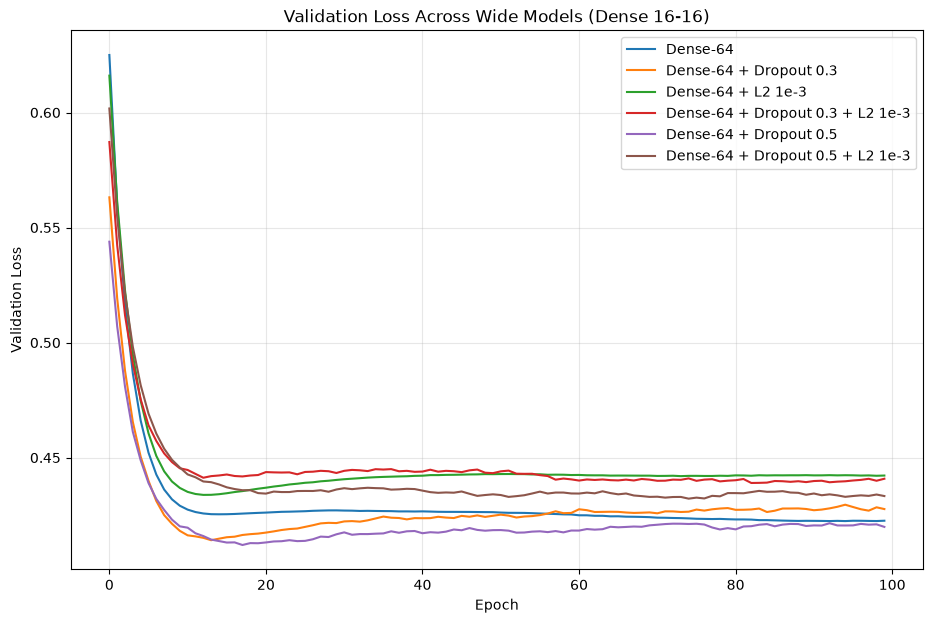

In [22]:
plt.figure(figsize=(11, 7))

for name, model, hist, dropout, l2 in wide_models:
    plt.plot(
        hist.history['val_loss'],
        label=name
    )

plt.xlabel('Epoch')
plt.ylabel('Validation Loss')
plt.title('Validation Loss Across Wide Models (Dense 16-16)')
plt.legend()
plt.grid(alpha=0.3)
plt.show()

## 7.2 Regularising the **Deep Model**



In [23]:
# regularisation experiment
deep_models = []

# tuple: model name, regularisation, l2
deep_reg_configs = [
    ('Dense-16-16',                           0.0,   0.000),
    ('Dense-16-16 + Dropout 0.3',             0.3,   0.000),
    ('Dense-16-16 + L2 1e-3',                 0.0,   0.001),
    ('Dense-16-16 + Dropout 0.3 + L2 1e-3',   0.3,   0.001),
    ('Dense-16-16 + Dropout 0.5',             0.5,   0.000),
    ('Dense-16-16 + Dropout 0.5 + L2 1e-3',   0.5,   0.001),
]

for name, dropout, l2 in deep_reg_configs:

    model = construct_neural_network(hidden_units=(16,16),dropout=dropout,l2=l2)

    hist = model.fit(
        X_train_p,
        y_train,
        epochs=100,
        validation_data=(X_val_p, y_val),
        verbose=0
    )
    print("Done fitting:", name)

    deep_models.append(
        (name, model, hist, dropout, l2)
    )

Done fitting: Dense-16-16
Done fitting: Dense-16-16 + Dropout 0.3
Done fitting: Dense-16-16 + L2 1e-3
Done fitting: Dense-16-16 + Dropout 0.3 + L2 1e-3
Done fitting: Dense-16-16 + Dropout 0.5
Done fitting: Dense-16-16 + Dropout 0.5 + L2 1e-3


In [24]:

deep_reg_table = build_reg_table(deep_models)
display(deep_reg_table.style.hide(axis="index"))

Model,Dropout,L2,Params,Best Epoch,Min val_loss,Best Val Accuracy,Train Loss @ Best,Loss Gap @ Best
Dense-16-16 + Dropout 0.3,0.300000,0.000000,433,74,0.415200,0.785700,0.454000,0.038800
Dense-16-16 + Dropout 0.5,0.500000,0.000000,433,93,0.415500,0.798700,0.479000,0.063500
Dense-16-16,0.000000,0.000000,433,18,0.422300,0.779200,0.443400,0.021200
Dense-16-16 + Dropout 0.5 + L2 1e-3,0.500000,0.001000,433,96,0.441600,0.772700,0.494700,0.053100
Dense-16-16 + L2 1e-3,0.000000,0.001000,433,25,0.442900,0.772700,0.460700,0.017900
Dense-16-16 + Dropout 0.3 + L2 1e-3,0.300000,0.001000,433,97,0.462000,0.779200,0.472100,0.010000


## 7.3 Alternative Method: Reducing Model Size
DLWP is explicit that the simplest way to fight overfitting is often simply to use a smaller model. A two-stage search is used here: first the width of a single hidden layer is swept (no regularisation), then light dropout is layered on top of whichever width performs best.

In [25]:
# # Dense-16 model

narrower_models = []

# tuple: model name, model version
NARROW_MODEL_CONFIG = [
    ('Compact-16',                            0.0,   0.000),
    ('Compact-16 + Dropout 0.3',              0.3,   0.000),
    ('Compact-16 + L2 1e-3',                  0.0,   0.001),
    ('Compact-16 + Dropout 0.3 + L2 1e-3',    0.3,   0.001),
    ('Compact-16 + Dropout 0.5',              0.5,   0.000),
    ('Compact-16 + Dropout 0.5 + L2 1e-3',    0.5,   0.001),
]

for name, dropout, l2 in NARROW_MODEL_CONFIG:

    model = construct_neural_network(hidden_units=(64, 64),dropout=dropout,l2=l2)

    hist = model.fit(
        X_train_p,
        y_train,
        epochs=100,
        validation_data=(X_val_p, y_val),
        verbose=0
    )
 
    narrower_models.append(
        (name, model, hist, dropout, l2)
    )

In [26]:
narrower_models_table = build_reg_table(narrower_models)
display(narrower_models_table.style.hide(axis="index"))

Model,Dropout,L2,Params,Best Epoch,Min val_loss,Best Val Accuracy,Train Loss @ Best,Loss Gap @ Best
Compact-16,0.000000,0.000000,4801,5,0.413100,0.818200,0.450800,0.037700
Compact-16 + Dropout 0.3,0.300000,0.000000,4801,6,0.422000,0.766200,0.473500,0.051500
Compact-16 + Dropout 0.5,0.500000,0.000000,4801,22,0.422000,0.766200,0.460400,0.038500
Compact-16 + Dropout 0.5 + L2 1e-3,0.500000,0.001000,4801,96,0.457100,0.785700,0.456000,0.001100
Compact-16 + Dropout 0.3 + L2 1e-3,0.300000,0.001000,4801,87,0.459100,0.779200,0.449100,0.010000
Compact-16 + L2 1e-3,0.000000,0.001000,4801,30,0.479500,0.785700,0.433900,0.045500


## Section 7.4: Short-listing Via Cross Validation

This section extracts the best models from Sections 7.1. 7.2 and 7.3 and re-run them with k-fold cross-validation to pick a single winner and the single train/val split on 768 rows is too noisy to trust. From this shortlisting, there will be a best performing model which the project wil train more on all of train/val/test then in 5-fold.

## 7.4 Short-listing via Cross-Validation

The 60/20/20 hold-out split used in Sections 5–7 provides a convenient way to compare models, but the results can be sensitive to the particular split, especially with only 768 observations. Sections 7.1–7.3 identified three promising model types: a **regularised wide model**, a **regularised deep model**, and a **compact model with reduced capacity**. However, the differences in their best validation results were relatively small, meaning that the ranking could have been influenced by the choice of training and validation data.

Following the approach described in DLWP Section 4.2.2, **k-fold cross-validation** is used to obtain a more reliable comparison when the dataset is limited. In this approach, the data is divided into several folds, with each observation used for validation once and for training in the remaining folds. The results from the folds can then be averaged to reduce the effect of a single train/validation split.

Therefore, **5-fold stratified cross-validation** is applied to the strongest candidates identified in Sections 7.1–7.3. The purpose is to determine whether the differences observed in the previous sections remain consistent across different splits and to select a single model for final training and testing in Section 8.

### Hypothesis

If the differences observed in Sections 7.1–7.3 are due to genuine differences in model performance, the stronger models should continue to perform well across the five folds.

If the differences were mainly caused by variation in the original train/validation split, the model rankings may change across folds and the candidates may perform similarly overall. In this case, following the Occam's razor principle discussed in DLWP Section 4.5.7, the simpler model would be preferred because it achieves similar performance with lower complexity.


In [27]:
# (name, hidden_units, dropout, l2   )
shortlist_configs = [
    # (name,                        hidden_units,  dropout, l2   )
    ('Wide-64 + Dropout 0.5',       (64,),         0.5,     0.000),   # section 7.1 winner
    ('Deep-16-16 + Dropout 0.3',    (16, 16),      0.3,     0.000),   # section 7.2 winner
    ('Compact Dense(24)',           (24,),         0.0,     0.000),   # section 7.3 winner (put your best_width here)
]


In [28]:
# shortlist as dict — cfg is already a kwargs dict for construct_neural_network
SHORTLIST = {
    'Wide-64 + Dropout 0.5':        dict(hidden_units=(64,),         dropout=0.5, l2=0.0),
    'Deep-16-16 + Dropout 0.3':     dict(hidden_units=(16, 16),      dropout=0.3, l2=0.0),
    f'Compact Dense({24})':         dict(hidden_units=(24,), dropout=0.0, l2=0.0),
}

skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)

cv_rows = []
for name, cfg in SHORTLIST.items():
    fold_metrics = []
    for tr_idx, va_idx in skf.split(X_trainval, y_trainval):
        X_tr, X_va = X_trainval[tr_idx], X_trainval[va_idx]
        y_tr, y_va = y_trainval[tr_idx], y_trainval[va_idx]

        prep  = fit_prep(X_tr)                                      # refit prep in-fold
        model = construct_neural_network(**cfg)
        hist  = model.fit(prep(X_tr), y_tr, epochs=100, batch_size=16,
                          validation_data=(prep(X_va), y_va), verbose=0)

        i = int(np.argmin(hist.history['val_loss']))
        fold_metrics.append({
            'Best Epoch':        i + 1,
            'Best Val Accuracy': hist.history['val_accuracy'][i],
            'Min val_loss':      hist.history['val_loss'][i],
        })

    df = pd.DataFrame(fold_metrics)                                 # aggregation in one line
    cv_rows.append({
        'Model':             name,
        'Params':            model.count_params(),
        'Best Epoch (mean)': int(round(df['Best Epoch'].mean())),
        'CV Acc mean':       round(df['Best Val Accuracy'].mean(), 4),
        'CV Acc std':        round(df['Best Val Accuracy'].std(),  4),
        'CV Loss mean':      round(df['Min val_loss'].mean(), 4),
        'CV Loss std':       round(df['Min val_loss'].std(),  4),
    })

cv_table = pd.DataFrame(cv_rows).sort_values('CV Loss mean').reset_index(drop=True)
display(cv_table.style.hide(axis="index"))

Model,Params,Best Epoch (mean),CV Acc mean,CV Acc std,CV Loss mean,CV Loss std
Wide-64 + Dropout 0.5,641,30,0.780100,0.015500,0.441800,0.033000
Compact Dense(24),241,39,0.778500,0.019600,0.448600,0.038500
Deep-16-16 + Dropout 0.3,433,59,0.793100,0.017700,0.452600,0.033800


In [29]:
FINAL_NAME   = cv_table.iloc[0]['Model']
FINAL_CFG    = SHORTLIST[FINAL_NAME]                                # direct dict lookup
FINAL_EPOCHS = int(cv_table.iloc[0]['Best Epoch (mean)'])

print(f"Best-performing architecture: {FINAL_NAME}")
print("Best performing architecture: ", FINAL_NAME)
print("Configuration: ", FINAL_CFG)

display(Markdown(
    f"**Final architecture selection.** Cross-validation ranks **{FINAL_NAME}** at the top of the shortlist, "
    f"with **{cv_table.iloc[0]['CV Acc mean']:.1%} ± {cv_table.iloc[0]['CV Acc std']:.1%}** mean validation "
    f"accuracy and mean validation loss of **{cv_table.iloc[0]['CV Loss mean']:.4f} ± {cv_table.iloc[0]['CV Loss std']:.4f}** "
    f"across five stratified folds; the mean best epoch across folds was **{FINAL_EPOCHS}**. "
    f"The standard deviations in the table above show how narrowly the shortlisted configurations are separated "
    f"once split-to-split noise is accounted for — a reminder that the single hold-out split used in Sections 5–7.3 "
    f"for fast iteration is a screening tool, not a final verdict, exactly as anticipated when the evaluation "
    f"protocol was chosen in Section 3.2. **{FINAL_NAME}** "
    f"(architecture: `{FINAL_CFG['hidden_units'] or 'linear, no hidden layer'}`, "
    f"dropout={FINAL_CFG['dropout']}, L2={FINAL_CFG['l2']}) trained for **≈{FINAL_EPOCHS} epochs** "
    f"is carried forward as the final model in Section 8, where it will be retrained on the full `X_trainval` set "
    f"with early stopping and evaluated exactly once on the untouched `X_test`."
))

Best-performing architecture: Wide-64 + Dropout 0.5
Best performing architecture:  Wide-64 + Dropout 0.5
Configuration:  {'hidden_units': (64,), 'dropout': 0.5, 'l2': 0.0}


**Final architecture selection.** Cross-validation ranks **Wide-64 + Dropout 0.5** at the top of the shortlist, with **78.0% ± 1.6%** mean validation accuracy and mean validation loss of **0.4418 ± 0.0330** across five stratified folds; the mean best epoch across folds was **30**. The standard deviations in the table above show how narrowly the shortlisted configurations are separated once split-to-split noise is accounted for — a reminder that the single hold-out split used in Sections 5–7.3 for fast iteration is a screening tool, not a final verdict, exactly as anticipated when the evaluation protocol was chosen in Section 3.2. **Wide-64 + Dropout 0.5** (architecture: `(64,)`, dropout=0.5, L2=0.0) trained for **≈30 epochs** is carried forward as the final model in Section 8, where it will be retrained on the full `X_trainval` set with early stopping and evaluated exactly once on the untouched `X_test`.

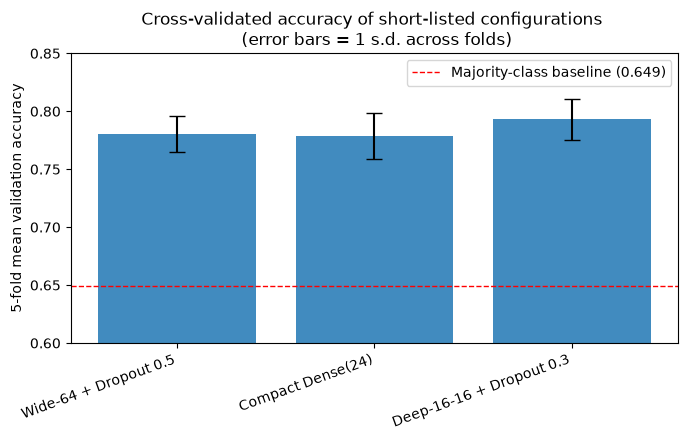

In [30]:
fig, ax = plt.subplots(figsize=(7, 4.5))
order = cv_table['Model'].tolist()
means = cv_table['CV Acc mean'].values
stds  = cv_table['CV Acc std'].values

ax.bar(order, means, yerr=stds, capsize=6, color='tab:blue', alpha=0.85)
ax.axhline(maj_val_acc, color='red', linestyle='--', linewidth=1,
           label=f'Majority-class baseline ({maj_val_acc:.3f})')
ax.set_ylabel('5-fold mean validation accuracy')
ax.set_ylim(0.6, 0.85)
ax.set_xticks(range(len(order)))
ax.set_xticklabels(order, rotation=20, ha='right')
ax.set_title('Cross-validated accuracy of short-listed configurations \n (error bars = 1 s.d. across folds)')
ax.legend()
fig.tight_layout()
plt.show()

# Section 8: Training on the Final model

In [38]:
# fit prep for full trainval sample using the best model
prep, stats = fit_prep(X_trainval) # Tip (1)
X_trainval_p = prep(X_trainval)
X_test_p = prep(X_test)

# not using regularisationexperiemnt() since it was for shortlisting
final_model = construct_neural_network(**FINAL_CFG)

final_model.fit(X_trainval_p, y_trainval, epochs=FINAL_EPOCHS, batch_size=16, verbose=0)

final_model.save("./app/model.keras")
# source for methods: https://keras.io/api/models/model_training_apis/
test_probs = final_model.predict(X_test_p, verbose=0).ravel() # 1-dimensional arr

# binary classification on seperating sigmoid probabilities
test_pred_positive = (test_probs >= 0.5).astype(int)

In [ ]:
export_prep = {
    "feature_order": feature_cols,
    "zero_as_missing": cols_with_zeros,
    "medians": stats["medians"].tolist(),
    "mean": stats["mean"].tolist(),
    "std": stats["std"].tolist(),
}

print(export_prep)
for key, value in export_prep.items():
    print(key, type(value))

# dumping into the json
with open("app/preprocessing.json", "w") as f:
    json.dump(export_prep, f, indent=2)


{'feature_order': ['Pregnancies', 'Glucose', 'BloodPressure', 'SkinThickness', 'Insulin', 'BMI', 'DiabetesPedigreeFunction', 'Age'], 'zero_as_missing': ['Glucose', 'BloodPressure', 'SkinThickness', 'Insulin', 'BMI'], 'medians': [3.0, 117.0, 72.0, 29.0, 125.0, 32.400001525878906, 0.3824999928474426, 29.0], 'mean': [3.819218158721924, 121.67101287841797, 72.14006805419922, 29.04234504699707, 137.70521545410156, 32.44820785522461, 0.4774276912212372, 33.366451263427734], 'std': [3.31144380569458, 29.979354858398438, 12.26512622833252, 8.884611129760742, 78.70064544677734, 6.8185625076293945, 0.33003124594688416, 11.8237943649292]}
feature_order <class 'list'>
zero_as_missing <class 'list'>
medians <class 'list'>
mean <class 'list'>
std <class 'list'>


In [59]:
# checking the json file
with open("app/preprocessing.json") as f:
    loaded = json.load(f)

print(loaded.keys())
print(len(loaded["mean"]))                                     # should be 8
print(np.allclose(loaded["mean"], stats["mean"]))              # should be True

dict_keys(['feature_order', 'zero_as_missing', 'medians', 'mean', 'std'])
8
True


In [ ]:
# test_predictions.csv

test_results = pd.DataFrame({
    "probability": test_probs,    # from Section 8
    "actual": y_test       # the true labels
})

test_results.to_csv("app/test_prediction", index=False)
print(test_results.tail())

     probability  actual
149     0.003213     0.0
150     0.056072     0.0
151     0.102990     0.0
152     0.906057     1.0
153     0.013416     0.0


In [ ]:
cv_table.to_csv("app/cv_results.csv", index=False)

In [ ]:
# majority_class var from seciton 5
maj_test_acc = (y_test == majority_class).mean()

# metrics for comparing with test sample and prediction
accuracy = accuracy_score(y_test, test_pred_positive)
precision = precision_score(y_test, test_pred_positive)
recall = recall_score(y_test, test_pred_positive)
f1 = f1_score(y_test, test_pred_positive)
roc_auc = roc_auc_score(y_test, test_probs)

test_metrics = {
    'Accuracy': accuracy,
    'Precision (diabetic)': precision,
    'Recall (diabetic)': recall,
    'F1-score (diabetic)': f1,
    'ROC-AUC': roc_auc
}

# display(pd.DataFrame(test_metrics, index=['Test-set value']))
display(pd.DataFrame(test_metrics, index=['Test-set value']).T.style.format('{:.4f}'))


,Test-set value
Accuracy,0.7273
Precision (diabetic),0.6111
Recall (diabetic),0.6111
F1-score (diabetic),0.6111
ROC-AUC,0.8128


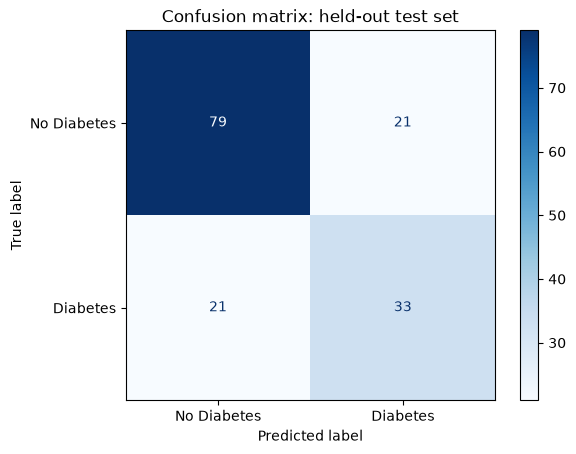

              precision    recall  f1-score   support

 No Diabetes       0.79      0.79      0.79       100
    Diabetes       0.61      0.61      0.61        54

    accuracy                           0.73       154
   macro avg       0.70      0.70      0.70       154
weighted avg       0.73      0.73      0.73       154



In [ ]:
# source: https://scikit-learn.org/stable/modules/generated/sklearn.metrics.confusion_matrix.html
cm = confusion_matrix(y_test, test_pred_positive)
disp = ConfusionMatrixDisplay(confusion_matrix=cm,
                              display_labels=['No Diabetes', 'Diabetes'])

disp.plot(cmap='Blues')
plt.title('Confusion matrix: held-out test set')
plt.grid(False)
plt.show()

# source: https://scikit-learn.org/stable/modules/generated/sklearn.metrics.classification_report.html
print(classification_report(y_test, test_pred_positive, target_names=['No Diabetes', 'Diabetes']))


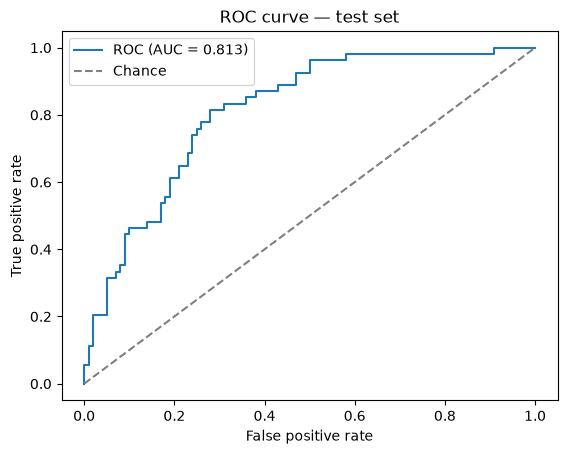

In [ ]:
# source: https://www.geeksforgeeks.org/machine-learning/auc-roc-curve/
fpr , tpr, _ = roc_curve(y_test, test_probs)

plt.plot(fpr, tpr, color='tab:blue', label=f"ROC (AUC = {test_metrics['ROC-AUC']:.3f})")
plt.plot([0, 1], [0, 1], linestyle='--', color='grey', label='Chance')
plt.xlabel('False positive rate')
plt.ylabel('True positive rate')
plt.title('ROC curve — test set')
plt.legend()
plt.show()

In [ ]:
display(Markdown(
f" **Final result:** On the held-out test set, which was used by the model for the first and only time during evaluation, **{FINAL_NAME}** achieved an accuracy of **{test_metrics['Accuracy']:.1%}**."
f"In addition to accuracy, the model achieved a recall of **{test_metrics['Recall (diabetic)']:.1%}** for the diabetic class and an ROC-AUC of **{test_metrics['ROC-AUC']:.3f}**. The confusion matrix above shows **{cm[1,0]} false negatives**, representing diabetic patients that were incorrectly classified as non-diabetic, compared with **{cm[0,1]} false positives**. This balance between missed cases and false alarms, as well as how it could be adjusted, is discussed further in Section 9."
))

 **Final result:** On the held-out test set, which was used by the model for the first and only time during evaluation, **Deep-16-16 + Dropout 0.3** achieved an accuracy of **72.7%**.In addition to accuracy, the model achieved a recall of **61.1%** for the diabetic class and an ROC-AUC of **0.813**. The confusion matrix above shows **21 false negatives**, representing diabetic patients that were incorrectly classified as non-diabetic, compared with **21 false positives**. This balance between missed cases and false alarms, as well as how it could be adjusted, is discussed further in Section 9.

# 9. Interpretation of Results
With the workflow or model trainings completed, this section focuses on a targeted analysis of the dataset and final model to investigate the factors influencing its performance. This analysis focuses on identifying where the model performs well, where errors occur and how its predictions could be adjusted for different real-world costs.

## 9.1 ROC curve and precision/recall trade-off
The model outputs a continuous probability rather than directly predicting 0 or 1 for labels. The 0.5 cut-off used in Section 8 is a chosen threshold, hence, the probabilities of 0.5 or above are classified as diabetic. However, this threshold can be changed depending on the purpose of the model. The ROC curve shows how the model performs across the different thresholds, while precision-recall curve shows the trade-off between precision and recall. For a screening context, using a lower threshold (`< 0.5`) can increase recall, which helps reduce the number of diabetic patients that are missed although this may also result in more **false positives**. 

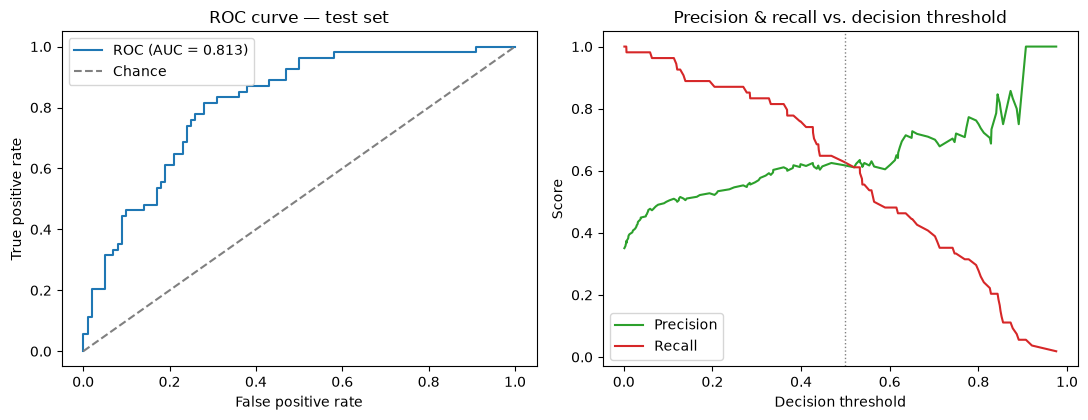

In [ ]:
fpr, tpr, roc_thresh = roc_curve(y_test, test_probs)
prec, rec, pr_thresh = precision_recall_curve(y_test, test_probs)

fig, axes = plt.subplots(1, 2, figsize=(11, 4.3))

axes[0].plot(fpr, tpr, color='tab:blue', label=f"ROC (AUC = {test_metrics['ROC-AUC']:.3f})")
axes[0].plot([0, 1], [0, 1], linestyle='--', color='grey', label='Chance')
axes[0].set_xlabel('False positive rate'); axes[0].set_ylabel('True positive rate')
axes[0].set_title('ROC curve — test set'); axes[0].legend()

axes[1].plot(pr_thresh, prec[:-1], label='Precision', color='tab:green')
axes[1].plot(pr_thresh, rec[:-1], label='Recall', color='tab:red')
axes[1].axvline(0.5, color='grey', linestyle=':', linewidth=1)
axes[1].set_xlabel('Decision threshold'); axes[1].set_ylabel('Score')
axes[1].set_title('Precision & recall vs. decision threshold'); axes[1].legend()

fig.tight_layout()
plt.show()

In this `Precision & recall vs. decision threshold` graph (at the right) illustrates the resulting trade-off when the decision threshold between recall and precision. As shown in the graph, lowering the threshold below 0.5 increases recall by identifying more potential diabetic cases, but this comes at the cost of reduced precision due to a higher number of **false-positive predictions**. 


## 9.2 Ethical Dilemma
For a clinical screening tool, rather than a diagnostic system, selecting a lower threshold may be more appropriate, given that reducing the number of missed diabetic patients can be prioritised over minimising the false positives. The statistical representation of the graph demonstrate the available trade-offs which can contribute the medicial decision of the usage of the neural network in the clinical setting.

## 9.3 Evaluating the Correct Prediction

The raw, unscaled feature values of test patients are compared between cases that were correctly classified by the final model and those that were misclassified. This analysis aims to determine whether the model's prediction errors show any identifiable patterns or clusters that can be interpreted meaningfully.

In [ ]:
# find which predictions were wrong (boolean)
wrong_prediction = test_pred_positive != y_test.astype(int)

# creating dataframe
test_data = pd.DataFrame(X_test, columns=feature_cols)

# add the actual outcome
test_data['Outcome'] = y_test.astype(int)

# label each row as Correct or Misclassified based on wrong_prediction boolean
test_data['Prediction_Result'] = np.where( wrong_prediction, 'Misclassified', 'Correct')


# calculate the average value of each feature
# separately for Correct and Misclassified predictions 
average_features = test_data.groupby(
    'Prediction_Result'
)[feature_cols].mean()

# transposing the table 
error_summary = average_features.T

# adding differnce column
error_summary['Difference'] = (
    error_summary['Misclassified'] - error_summary['Correct']
)

error_summary = error_summary.sort_values( 'Difference', key=abs, ascending=False)

display(
    error_summary.style.format('{:.3f}')
)

Prediction_Result,Correct,Misclassified,Difference
Insulin,78.527,99.762,21.235
Glucose,115.866,134.095,18.229
BloodPressure,66.500,71.119,4.619
BMI,31.291,34.145,2.854
Age,32.116,34.405,2.289
Pregnancies,3.634,4.786,1.152
SkinThickness,19.580,19.571,-0.009
DiabetesPedigreeFunction,0.448,0.455,0.008


In [ ]:
# extracting average difference value from the finding
difference = error_summary['Misclassified'] - error_summary['Correct']
n_wrong = int(wrong_prediction.sum())
n_total = len(y_test)

In [ ]:
display(Markdown(f"""
### Report
Of the {n_total} test patients, **{n_wrong}** were misclassified ({n_wrong/n_total*100:.1f}%). The largest differences were in **Insulin** ({difference['Insulin']:+.1f}) and **Glucose** ({difference['Glucose']:+.1f}). However, the Insulin difference should be treated cautiously because many values are recorded as zero.

The more reliable finding is the **{difference['Glucose']:+.1f} mg/dL Glucose gap**. Misclassified patients also tended to have higher BloodPressure, BMI, Age and Pregnancies. This suggests that the model performs better on clearly healthy or diabetic patients but struggles more with patients near the decision boundary.

"""))


### Report
Of the 154 test patients, **42** were misclassified (27.3%). The largest differences were in **Insulin** (+21.2) and **Glucose** (+18.2). However, the Insulin difference should be treated cautiously because many values are recorded as zero.

The more reliable finding is the **+18.2 mg/dL Glucose gap**. Misclassified patients also tended to have higher BloodPressure, BMI, Age and Pregnancies. This suggests that the model performs better on clearly healthy or diabetic patients but struggles more with patients near the decision boundary.



## 9.4 Permutation feature importance (linear baseline)

Because the network is restricted to `Dense/Dropout layers`, tree-model importance metrics such
as impurity-based Gini importance are not applicable. Instead, this section uses **permutation
feature importance**, a model-agnostic method introduced by Breiman (2001) and available in
scikit-learn: for each feature, the values in the test set are **randomly shuffled** and the drop
in test accuracy is recorded. A feature whose shuffling causes a large accuracy drop is one
the model relies on heavily; a feature whose shuffling barely changes accuracy is contributing
little.

The importance is computed on the logistic-regression baseline from **Section 5** rather than the
final neural network, for two reasons: Section 5 established that the two models perform
comparably on this dataset, so the linear baseline is a fair proxy for what the network has
learnt; sklearn's `permutation_importance` accepts scikit-learn estimators directly
without the wrapping code required to apply it to a Keras model.

In [ ]:
# Source: https://scikit-learn.org/stable/modules/permutation_importance.html

# permutation used on lr_baseline
perm = permutation_importance(lr_baseline, X_test_p, y_test,
                              n_repeats=30, random_state=SEED, scoring='accuracy')


perm_tbl = pd.DataFrame({
    'Feature': feature_cols,
    'Importance (mean acc. drop)': perm.importances_mean,
    'Std across shuffles': perm.importances_std,
}).sort_values('Importance (mean acc. drop)', ascending=False).reset_index(drop=True)

display(perm_tbl.style.format({
    'Importance (mean acc. drop)': '{:.4f}',
    'Std across shuffles': '{:.4f}'}))

,Feature,Importance (mean acc. drop),Std across shuffles
0,Glucose,0.0688,0.0228
1,Age,-0.0006,0.0061
2,Insulin,-0.0015,0.0060
3,SkinThickness,-0.0017,0.0044
4,BMI,-0.0080,0.0271
5,DiabetesPedigreeFunction,-0.0084,0.0104
6,Pregnancies,-0.0123,0.0131
7,BloodPressure,-0.0141,0.0077


# 9.5 Limitation

The project has gone through several limitations that should be considered in interpreting the results
* **Population specificity:** The dataset contains 768 records from adult female patients of Pima heritage from specific population. Hence, the sample is too limited to represent the general population. Applying the model to a different population would require additional data and further validation 
* **Imputation assumptions:**: A large proportion of the `Insulin` values and substantial number of `SkinThickness` values were replaced during median imputation (Section 4). Although this provides a simple approach while avoiding data leakage, it removes information about original missing values. Patients whose true values differ systematically from the median could be biased by the imputation, and this is a plausible contributor to the noisy Insulin gap observed in Section 9.3.
* **Dataset size:** The dataaset contains 768 sample, so the results are sensitive to how the data are divided between training and validation sets. The s.t.d from the 5-fold-cross validation in section 7.3 show some variations between folds (ranging between one to two percentage points around the mean validation accuracy). The 154-patient test set in Section 8 gives a single point estimate rather than a distribution. A larger and more diverse cohort would tighten both the model-selection decision and the final headline number.
* **Threshold:** The 0.5 decision threshold used to convert Section 8's continuous probability output into 0/1 labels is a convention rather than a clinical requirement. Section 9.1 showed how the precision and recall trade off across thresholds, and a real deployment would need this threshold set deliberately by a domain expert to reflect the cost of a missed diabetic patient against the cost of a false alarm.


# 10. Conclusions
## 10.1 Addressing the Hypotheses from Section 1.4
The two working hypotheses set out in Section 1.4 are revisited here in light of the results from Sections 5–9.

In [ ]:
display(Markdown(f"""
- **Learnability Hypothesis (Supported):** Every model trained in this report, including the
  single-layer linear baseline, comfortably cleared the majority-class baseline of
  {maj_val_acc*100:.1f}% (Section 5), and the final model achieves a test-set accuracy of
  **{test_metrics['Accuracy']*100:.1f}%** with a ROC-AUC of **{test_metrics['ROC-AUC']:.3f}**
  on data it had never seen **(Section 8)**. The eight input features carry real, extractable
  predictive signal about diabetes onset in this cohort.

- **Sufficiency Hypothesis (partially supported):** The dataset is large enough to train models
  that clearly beat the baseline, but Section 6 showed that networks with more than a
  handful of hidden units overfit within a few epochs, and the cross-validated performance
  estimates in Section 7.4 carry standard deviations of roughly one to two percentage
  points, which is on the same order as the differences between shortlisted configurations.
  The ceiling reached here appears to be a *data ceiling* rather than a *capacity ceiling*;
  a larger and more diverse cohort would likely still improve results.
"""))


- **Learnability Hypothesis (Supported):** Every model trained in this report, including the
  single-layer linear baseline, comfortably cleared the majority-class baseline of
  64.9% (Section 5), and the final model achieves a test-set accuracy of
  **72.7%** with a ROC-AUC of **0.813**
  on data it had never seen **(Section 8)**. The eight input features carry real, extractable
  predictive signal about diabetes onset in this cohort.

- **Sufficiency Hypothesis (partially supported):** The dataset is large enough to train models
  that clearly beat the baseline, but Section 6 showed that networks with more than a
  handful of hidden units overfit within a few epochs, and the cross-validated performance
  estimates in Section 7.4 carry standard deviations of roughly one to two percentage
  points, which is on the same order as the differences between shortlisted configurations.
  The ceiling reached here appears to be a *data ceiling* rather than a *capacity ceiling*;
  a larger and more diverse cohort would likely still improve results.


## 10.2 What the workflow revealed

Working through the seven stages of DLWP §4.5 surfaced several concrete findings that were not assumed at the start of the project.

* **Linear model does most of the work on this dataset.** The logistic-regression baseline in Section 5 came within a small margin of every neural network trained in Sections 6 and 7, and the compact Dense architecture in Section 7.3 tied or beat the wider and deeper regularised variants on cross-validated loss. Taken together, this suggests the true decision boundary between diabetic and non-diabetic patients in the Pima dataset is close to linear rather than deeply non-linear, and the marginal value of a hidden-layer neural network on this problem is small.

* **Reducing model size was at least as effective as dropout or L2 regularisation.** The regularisation experiments in Sections 7.1 and 7.2 showed that dropout materially reduced the train/validation loss gap on the `Dense-64` and `Dense-16-16` architectures, but Section 7.3 demonstrated that a smaller unregularised architecture could achieve comparable validation performance with a fraction of the parameters. This is a data-driven confirmation of DLWP §4.4.1's guidance that "the simplest fix for overfitting is often to use a smaller model" on small tabular problems.

* **A single hold-out split is not the end of the story on 768 records.** The cross-validation step in Section 7.4 visibly re-ordered several shortlisted configurations whose single-split validation scores had placed them within a percentage point of each other, confirming why the evaluation protocol was chosen deliberately in Section 3 rather than defaulted to. Standard deviations of one to two percentage points across five folds also mean that small headline differences between architectures should not be over-interpreted.

* **Glucose is the dominant predictor by three independent measures.** The error analysis in Section 9.3 identified plasma glucose concentration as the single largest gap between correctly and misclassified patients, the permutation-importance analysis in Section 9.4 ranked it highest by mean accuracy drop when shuffled, and the wider medical literature on this cohort (Smith et al., 1988) identifies it as the strongest clinical predictor of diabetes onset. This triple agreement provides confidence that the model has learnt a clinically meaningful signal rather than an artefact of the imputation pipeline.


## 10.3 Future work

With additional time or data, the natural next steps would be:

* **Collect more records.** The cross-validation standard deviations in Section 7.4 and the 154-patient test set in Section 8 both point to the same underlying constraint: 768 rows is small. A larger and more diverse cohort would tighten the model-selection decision and narrow the confidence interval around the final headline number.

* **Improve missing-value handling.** Roughly half of the `Insulin` column and a substantial share of `SkinThickness` were reconstructed via median imputation in Section 4, and Section 9.3 showed that this contributes noise to the Insulin gap between correct and misclassified patients. Adding an explicit missingness-indicator column, or fitting a model that natively handles missing values, would likely improve performance on those affected features.

* **Validate against a second cohort.** The Section 9.5 limitation on population specificity is fundamental to this dataset and cannot be addressed within it. Re-validating the trained model against a second, independently-collected diabetes cohort (of different ethnic composition, or including male patients) would test whether the learnt relationship generalises beyond the original Pima study population.

# References: 

1. Chollet, F. (2018). Deep learning with python. Manning, Cop. https://www.manning.com/books/deep-learning-with-python

2. GeeksforGeeks. (2024, March 26). Dropout Regularization in Deep Learning. GeeksforGeeks. https://www.geeksforgeeks.org/deep-learning/dropout-regularization-in-deep-learning/

3. Breiman, L. (2001). Random forests. https://www.stat.berkeley.edu/~breiman/randomforest2001.pdf

4. Smith, J. W., Everhart, J. E., Dickson, W. C., Knowler, W. C., & Johannes, R. S. (1988). Using the ADAP learning algorithm to forecast the onset of diabetes mellitus. Proc. Symp. Comp. Appl. Med. Care, 261–265.

5. scikit-learn documentation. https://scikit-learn.org/stable/

6. Keras documentation. https://keras.io/api/